In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path().resolve().parent / "src"))
from lcoe import CostParams, system_cost, baseline_cost

import itertools
from itertools import chain, combinations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Input and output paths
ROOT = Path().resolve().parent
RAW  = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed' 
FIG = ROOT / 'results' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

In [3]:
raw_data = pd.read_csv(PROCESSED / "dataset_filtered.csv")
raw_data.info()
df = raw_data.copy()

<class 'pandas.DataFrame'>
RangeIndex: 2525 entries, 0 to 2524
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   well_id                2525 non-null   str    
 1   easting                2525 non-null   float64
 2   northing               2525 non-null   float64
 3   depth_tvd_m            2525 non-null   float64
 4   porosity_pct           2525 non-null   float64
 5   bulk_density_gcc       2525 non-null   float64
 6   formation_thickness_m  2525 non-null   float64
 7   distance_to_usp_km     2525 non-null   float64
 8   temp_harrison          2525 non-null   float64
 9   temp_res_c             2525 non-null   float64
 10  permeability_md        2525 non-null   float64
 11  k_log                  2525 non-null   float64
dtypes: float64(11), str(1)
memory usage: 236.8 KB


In [4]:
HEATING_TARGET = 10   #MW
COOLING_TARGET = 5    #MW

WELLS = df["well_id"].unique().tolist()

In [5]:
wells_base = {
    row["well_id"]: {
        "Easting" : row["easting"],
        "Northing":row["northing"],
        "Thickness": row["formation_thickness_m"],
        "Permeability": row["permeability_md"] * 9.869e-16,
        "Transmissivity": row["formation_thickness_m"] * row["permeability_md"] * 9.869e-16,
        "Temperature": row["temp_res_c"],
        "Depth": row["depth_tvd_m"]
    }
    for _, row in df.iterrows()
}

### Flow Rate and Thermal Power

$$\mu = 2.414 \times 10^{-5} \times 10^{\frac{247.8}{T + 133.15}}$$

$$Q=\frac{2\pi T\Delta P}{\mu (\ln (r_{e}/r_{w}) + S)}$$

$$ P_{th} = \dot{m}C_p(T_p - T_r)$$

In [6]:
def flow_rate_and_thermal_power(kh, T, T_r=40, rho_water=970, cp_water=4186, delta_p=18e5, r_e=1000, r_w=8 * 0.0254 / 2, skin=-1):
    """
    Calculates radial flow rate (q) and thermal power (P_th) for a water well.
    
    Parameters:
    kh        : Permeability-thickness product in m^3 (Transmissibility)
    T         : Temperature of the produced water in Celsius
    T_r       : Reinjection/reference temperature in Celsius (default: 40 C)
    rho_water : Density of water in kg/m^3 (default: 970)
    cp_water  : Specific heat capacity of water in J/(kg*K) (default: 4186)
    delta_p   : Pressure drawdown in Pascals (default: 1.8 MPa)
    r_e       : External/drainage radius in meters (default: 1000 m)
    r_w       : Wellbore radius in meters (default: 4 inches converted to meters)
    
    Returns:
    q         : Volumetric flow rate in m^3/s
    P_th_MW   : Thermal power in Megawatts (MW)
    """
    # Calculate dynamic viscosity of water as a function of temperature (Celsius)
    mu = 2.414e-5 * 10 ** (247.8 / (T + 133.15))

    # Radial flow rate using Darcy's Law
    q = (2 * np.pi * kh * delta_p) / (mu * (np.log(r_e / r_w) + skin))

    # Mass flow rate (kg/s)
    m_dot = rho_water * q
    T_p = T 

    # Thermal power in Watts, then converted to Megawatts
    P_th = m_dot * cp_water * (T_p - T_r)
    P_th_MW = P_th / 1e6

    return q, P_th_MW

In [7]:
def evaluate(well, power):
    gap = HEATING_TARGET - power
    if power > HEATING_TARGET:
        print(f"\n{well}meets both heating and cooling targets.\nTarget exceeded by {-gap:.2f} MW")
    elif power > COOLING_TARGET:
        print(f"\n{well} meets cooling target only.\n{gap:.2f} MW required to reach heating target.")
    else: 
        print(f"\n{well} does not meet heating or cooling target.\n{gap:.2f} MW required to reach heating target.")

    print(f"{well}'s thermal power is {power:.2f} MW")

### Modelling Thermal Interference

In [8]:
from scipy.special import exp1

# Constants
rho_w, g = 1000.0, 9.81
Ss, cw_vol, caq_vol = 1e-6, 4.18e6, 2.3e6   # specific storage, volumetric heat capacity of water, volumetric heat capacity of saturated rock
years = 30
t = years * 365.25 * 24 * 3600              # time in seconds

# Assumed inputs
Q = 150 / 3600   # m3/s 
d = 1500         # m
az = {"BLT-01": 0.0, "JUT-01": 0.0}

# Building doublets
doub = {}
for name in wells_base:
    w = wells_base[name]
    a = np.radians(az[name])
    dx, dy = 0.5 * d * np.cos(a), 0.5 * d * np.sin(a)
    doub[name] = {"prod": (w["Easting"]-dx, w["Northing"]-dy, + Q),
                  "inj": (w["Easting"]+dx, w["Northing"]+dy, -Q)}

$$\text{Thermal Radius}$$
$$R_{th}=\sqrt {\frac{Q t c_{w}}{\pi H c_{aq}}}$$

$$\text{Thermal Breakthrough Time (Gringarten-type doublet model)}$$
$$t_{b}=t_{w} \cdot \frac{c_{aq}}{\phi c_{w}} = \frac{\pi d^{_2} H c_{aq}}{3 Q c_{w}}$$

In [9]:
# Thermal checks between producer-injector
for name in wells_base:
    w = wells_base[name]
    R_th = np.sqrt(Q * t * cw_vol/ (np.pi * w["Thickness"] * caq_vol))
    t_b = np.pi * d ** 2 * w["Thickness"] * caq_vol / (3 * Q * cw_vol) / (365 * 24 * 3600)
    print(f"\n{name}"
          f"\nCold front advances by {R_th:.0f} m after 30 years"
          f"\nd/2 = {d/2} m"
          f"\nBreakthrough will be in {t_b:.0f} years")


BLT-01
Cold front advances by 432 m after 30 years
d/2 = 750.0 m
Breakthrough will be in 121 years

JUT-01
Cold front advances by 426 m after 30 years
d/2 = 750.0 m
Breakthrough will be in 124 years


$$\text{Theis Solution}$$
$$\Delta T(r, t)=\frac{q}{4 \pi k} E{_1}(\frac{r^{2}}{4 \alpha t})$$

In [10]:
# Averaged properties
props = {}
for name in wells_base:
    w = wells_base[name]
    mu_water = 2.414e-5 * 10 ** (247.8 / (w["Temperature"] + 273.15 - 140))
    K = w["Permeability"] * rho_w * g / mu_water
    props[name] = {"T": K * w["Thickness"], "S": Ss * w["Thickness"]}

Th = np.sqrt(props["BLT-01"]["T"] * props["JUT-01"]["T"])
S  = 0.5 * (props["BLT-01"]["S"] + props["JUT-01"]["S"])    
print(f"Th = {Th:.2e} m2/s, S = {S:.2e}")

Th = 1.85e-04 m2/s, S = 1.24e-04


In [11]:
# Checking pressure interference
for src, tgt in [("BLT-01", "JUT-01"), ("JUT-01", "BLT-01")]:
    for role, (xt, yt, _) in doub[tgt].items():
        s = 0.0                        
        for xs, ys, q in doub[src].values():
            r = np.hypot(xt - xs, yt - ys)
            s += q / (4 * np.pi * Th) * exp1(r**2 * S / (4 * Th * t))
        print(f"{src} -> {tgt} {role}: {s:+.2f} m ({s*rho_w*g/1e5:+.3f} bar)")

BLT-01 -> JUT-01 prod: +4.62 m (+0.453 bar)
BLT-01 -> JUT-01 inj: +4.97 m (+0.488 bar)
JUT-01 -> BLT-01 prod: -4.97 m (-0.488 bar)
JUT-01 -> BLT-01 inj: -4.62 m (-0.453 bar)


In [12]:
L = np.hypot(wells_base["BLT-01"]["Easting"] - wells_base["JUT-01"]["Easting"],
             wells_base["BLT-01"]["Northing"] - wells_base["JUT-01"]["Northing"])

# Nearest well-to-well distance between the two doublets
d_min = min(np.hypot(x1 - x2, y1 - y2)
            for x1, y1, _ in doub["BLT-01"].values()
            for x2, y2, _ in doub["JUT-01"].values())

print(f"Doublet centre spacing: {L:.0f} m")
print(f"Nearest wells:          {d_min:.0f} m")

for name in wells_base:
    H = wells_base[name]["Thickness"]
    R_th = np.sqrt(Q * t * cw_vol / (np.pi * H * caq_vol))
    print(f"\n{name}: front = {R_th:.0f} m, {R_th/d_min*100:.1f}% of the nearest-well distance")
    t_reach = np.pi * H * d_min**2 * caq_vol / (Q * cw_vol) / (365.25 * 24 * 3600)
    print(f"{name}: front reaches the nearest well of the other doublet in {t_reach:,.0f} years")

Doublet centre spacing: 9084 m
Nearest wells:          7895 m

BLT-01: front = 432 m, 5.5% of the nearest-well distance
BLT-01: front reaches the nearest well of the other doublet in 10,029 years

JUT-01: front = 426 m, 5.4% of the nearest-well distance
JUT-01: front reaches the nearest well of the other doublet in 10,305 years


The doublets do not interfere thermally. They interfere hydraulically but only slightly

## Production Scenarios

### 1. One Doublet

In [13]:
q_blt_base, p_blt_base = flow_rate_and_thermal_power(kh=wells_base["BLT-01"]["Transmissivity"], T=wells_base["BLT-01"]["Temperature"])
q_jut_base, p_jut_base = flow_rate_and_thermal_power(kh=wells_base["JUT-01"]["Transmissivity"], T=wells_base["JUT-01"]["Temperature"])

print("===BaseCase Power===")
print(f"Heating Target = {HEATING_TARGET} MW")
print(f"Cooling Target = {COOLING_TARGET} MW")
evaluate("BLT-01", p_blt_base)
evaluate("JUT-01", p_jut_base)

===BaseCase Power===
Heating Target = 10 MW
Cooling Target = 5 MW

BLT-01 meets cooling target only.
3.75 MW required to reach heating target.
BLT-01's thermal power is 6.25 MW

JUT-01 does not meet heating or cooling target.
7.79 MW required to reach heating target.
JUT-01's thermal power is 2.21 MW


### 2. Two Doublets

In [14]:
p_total_base = p_blt_base + p_jut_base

print("===BaseCase Power===")
print(f"Heating Target = {HEATING_TARGET} MW")
print(f"Cooling Target = {COOLING_TARGET} MW")
evaluate("BLT-01 and JUT-01", p_total_base)

===BaseCase Power===
Heating Target = 10 MW
Cooling Target = 5 MW

BLT-01 and JUT-01 meets cooling target only.
1.54 MW required to reach heating target.
BLT-01 and JUT-01's thermal power is 8.46 MW


In [15]:
increase = (HEATING_TARGET - p_total_base) / p_total_base * 100

print("In order to meet our heating target, we need an increase in thermal power.\n"
    f"An increase in thermal power by {increase:.1f}% can be achieved by boosting flow rate by {increase:.1f}%\n"
    "(via stimulation, artificial lift/ESPs, or lateral sidetracks) "
    "or by lowering the reinjection temperature (T_r)."
    f"Cooling is a separate chiller plant. Our design runs on the assumption that heating and cooling do not happen simultaneously")

In order to meet our heating target, we need an increase in thermal power.
An increase in thermal power by 18.2% can be achieved by boosting flow rate by 18.2%
(via stimulation, artificial lift/ESPs, or lateral sidetracks) or by lowering the reinjection temperature (T_r).Cooling is a separate chiller plant. Our design runs on the assumption that heating and cooling do not happen simultaneously


## Well Interventions: Heating

In [16]:
interventions = {
    "none":           dict(skin=-1, T_r=30, hp=False, COP_hp=0.0),
    "thermogis_stim": dict(skin=-4, T_r=30, hp=False, COP_hp=0.0),
    "heat_pump":      dict(skin=-1, T_r=20,   hp=True, COP_hp=5.0),    
    "stim_hp":        dict(skin=-4, T_r=20,   hp=True, COP_hp=5.0),
}

def compute_well_power(well, method):
    q, p = flow_rate_and_thermal_power(
        kh=wells_base[well]["Transmissivity"],
        T=wells_base[well]["Temperature"],
        T_r=interventions[method]["T_r"],
        skin=interventions[method]["skin"]
    )
    return p * interventions[method]["COP_hp"] / (interventions[method]["COP_hp"] - 1) if interventions[method]["hp"] else p

def heat_pump_electricity(power_delivered_mw):
    return power_delivered_mw / interventions[method]["COP_hp"] if interventions["method"]["heat_pump"] else 0.0

### Grid Search

In [17]:
def well_subsets(wells):
    return chain.from_iterable(combinations(wells, r) for r in range(1, len(wells) + 1))

results = []
for subset in well_subsets(WELLS):
    for combo in itertools.product(interventions.keys(), repeat=len(subset)):
        detail, total_power = {}, 0

        for well, method in zip(subset, combo):
            p = compute_well_power(well, method)
            detail[well] = method
            detail[f"{well}_MW"] = round(p, 2)
            total_power += p

        for well in WELLS:
            if well not in subset:
                detail[well] = "not_drilled"
                detail[f"{well}_MW"] = 0.0

        detail["n_wells_used"] = len(subset)
        detail["total_MW"] = round(total_power, 2)
        detail["meets_heating"] = total_power >= HEATING_TARGET
        results.append(detail)

df_grid = pd.DataFrame(results).sort_values("total_MW")
df_grid

,BLT-01,BLT-01_MW,JUT-01,JUT-01_MW,n_wells_used,total_MW,meets_heating
4,not_drilled,0.00,none,2.92,1,2.92,False
6,not_drilled,0.00,heat_pump,4.53,1,4.53,False
5,not_drilled,0.00,thermogis_stim,4.60,1,4.60,False
7,not_drilled,0.00,stim_hp,7.15,1,7.15,False
0,none,7.82,not_drilled,0.00,1,7.82,False
8,none,7.82,none,2.92,2,10.74,True
2,heat_pump,11.74,not_drilled,0.00,1,11.74,True
1,thermogis_stim,12.34,not_drilled,0.00,1,12.34,True
10,none,7.82,heat_pump,4.53,2,12.35,True
9,none,7.82,thermogis_stim,4.60,2,12.42,True


In [18]:
therm_ds = pd.read_csv(PROCESSED / "thermogis_long.csv")
therm_ds = therm_ds[therm_ds["Well_ID"].isin(WELLS)]

def summarize_p10_p50_p90(values):
    """Reservoir convention: P10 = high case (90th percentile), P90 = low case (10th percentile)."""
    return {"P10_high": np.percentile(values, 90), "P50_median": np.percentile(values, 50),
            "P90_low": np.percentile(values, 10), "mean": np.mean(values), "std": np.std(values)}

# transmissivity P90/P50/P10 per well, straight from the ThermoGIS table (Dm)
trans = (therm_ds[therm_ds["Property"] == "Transmissivity"]
         .pivot_table(index="Well_ID", columns="Probability", values="Value", aggfunc="first"))
print(trans)

sig_by_well = {w: np.log(trans.loc[w, "P10"] / trans.loc[w, "P90"]) / (2 * 1.2816) for w in WELLS}
print({w: round(s, 2) for w, s in sig_by_well.items()})

Probability   P10  P50  P90
Well_ID                    
BLT-01       66.1  9.3  1.3
JUT-01       10.4  4.8  2.2
{'BLT-01': np.float64(1.53), 'JUT-01': np.float64(0.61)}


In [19]:
N = 10_000
DM_TO_M3 = 9.869e-13
COP_hp = 5.0
Q_pump_max = 250 /3600
rng_mc = np.random.default_rng(42)

def sample_transmissivity_m3(p90, p50, p10, n):
    """Lognormal fitted to ThermoGIS P90/P50/P10 (Dm), returned in m3."""
    sigma = np.log(p10 / p90) / (2 * 1.2816)
    return rng_mc.lognormal(np.log(p50), sigma, n) * DM_TO_M3

def mc_power(well, method, kh):
    """Heat delivered (MW) for an array of transmissivity draws."""
    iv = interventions[method]
    q, p = flow_rate_and_thermal_power(kh=kh, T=wells_base[well]["Temperature"],
                                       T_r=iv["T_r"], skin=iv["skin"])
    p = p * np.minimum(q, Q_pump_max) / q          # cap flow at the pump limit
    return p * COP_hp / (COP_hp - 1) if iv["hp"] else p

# one set of draws per well, reused for every intervention so comparisons are like for like
kh = {w: sample_transmissivity_m3(trans.loc[w, "P90"], trans.loc[w, "P50"], trans.loc[w, "P10"], N)
      for w in WELLS}

rows = []
for subset in well_subsets(WELLS):
    for combo in itertools.product(interventions.keys(), repeat=len(subset)):
        total = sum(mc_power(w, m, kh[w]) for w, m in zip(subset, combo))   # array of N values
        st = summarize_p10_p50_p90(total)
        rows.append(dict(config=" + ".join(f"{w}:{m}" for w, m in zip(subset, combo)),
                         P_meet_10MW=(total >= HEATING_TARGET).mean(),
                         P10_high_MW=st["P10_high"], P50_MW=st["P50_median"], P90_low_MW=st["P90_low"]))

mc_grid = pd.DataFrame(rows).sort_values("P_meet_10MW", ascending=False)
mc_grid.round(2)

,config,P_meet_10MW,P10_high_MW,P50_MW,P90_low_MW
23,BLT-01:stim_hp + JUT-01:stim_hp,0.87,32.49,23.76,9.10
15,BLT-01:thermogis_stim + JUT-01:stim_hp,0.82,25.79,17.74,7.83
19,BLT-01:heat_pump + JUT-01:stim_hp,0.81,31.23,19.84,7.70
21,BLT-01:stim_hp + JUT-01:thermogis_stim,0.80,28.28,22.02,6.89
22,BLT-01:stim_hp + JUT-01:heat_pump,0.80,28.25,22.11,6.82
11,BLT-01:none + JUT-01:stim_hp,0.75,24.73,16.27,6.74
20,BLT-01:stim_hp + JUT-01:none,0.74,25.61,20.38,5.42
13,BLT-01:thermogis_stim + JUT-01:thermogis_stim,0.73,21.36,15.70,5.93
14,BLT-01:thermogis_stim + JUT-01:heat_pump,0.72,21.45,15.79,5.87
17,BLT-01:heat_pump + JUT-01:thermogis_stim,0.72,27.38,16.28,5.83


### Surface Interventions: Cooling

In [20]:
# Design Assumptions
T_inj_base, T_inj_hp, COP_hp = 30.0, 20.0, 5.0
skin_base, skin_stim = -1.0, -4.0
eta_pump, rw = 0.6, 0.108                             # Pump efficiency; 8.5 inch well
Q_pump_max = 250 / 3600       # m3/s per doublet
sig_lnk = 0.5

# 30 year lifetime
YEAR_S = 365.25 * 24 * 3600
t30 = 30 * YEAR_S

# Cooling option
COOLING = "electric"          # "electric" chillers or "ates" (shallow aquifer storage)
COP_ch = 4.5
dT_cool = 6.0                 # K, temperature difference across the cooling loop
Q_ates_doublet = 200 / 3600   # m3/s one ATES doublet can carry
COP_ates = 20.0               # cooling delivered / electricity (pumps only)
ATES_RECOVERY = 0.0           # share of the heat injected in summer that is reused in winter

### Cost Assumptions

In [21]:
COST = CostParams()
print(f"Financing: {1 - COST.equity_share:.0%} loan at {COST.loan_rate:.0%}, equity return {COST.equity_return:.0%}, inflation {COST.inflation:.0%}, {COST.lifetime} years")

Financing: 80% loan at 5%, equity return 7%, inflation 2%, 15 years


In [22]:
heat_peak, cool_peak = HEATING_TARGET, COOLING_TARGET      # MW
LOAD_FACTOR_HEAT, LOAD_FACTOR_COOL = 0.4, 0.3              # ASSUMPTIONS: average demand / peak (test 0.25, 0.4, 0.6)
heat_MW = np.full(12, heat_peak * LOAD_FACTOR_HEAT)        
cool_MW = np.full(12, cool_peak * LOAD_FACTOR_COOL)
hrs = 730                                                  # hours per month

In [23]:
ORDER = sorted(WELLS, key=lambda w: -wells_base[w]["Transmissivity"])   # best well first
demand, cool = heat_MW, cool_MW

def mu_w(T): return 2.414e-5 * 10 ** (247.8 / (T + 273.15 - 140))

def design_wells(w, stim, hp, dP_bar, d_floor=500.0):
    T_inj = T_inj_hp if hp else T_inj_base
    skin = skin_stim if stim else skin_base
    Tp, H, k = w["Temperature"], w["Thickness"], w["Permeability"]
    Kp = k * rho_w * g / mu_w(Tp)
    Ki = k * rho_w * g / mu_w(T_inj)

    def flow(dd):
        res_ = (np.log(dd / rw) + skin) * (1 / (Kp * H) + 1 / (Ki * H)) / (2 * np.pi)
        return res_, min(dP_bar * 1e5 / (rho_w * g) / res_, Q_pump_max)
    
    dd = 1000.0
    for _ in range(10):
        res_, Q = flow(dd)
        dd = max(np.sqrt(3 * Q * cw_vol * t30 / (np.pi * H * caq_vol)), d_floor)
    res_, Q = flow(dd)
    dP = Q * res_ * rho_w * g
    return dict(Q=Q, d=dd, P_src=cw_vol * Q * (Tp - T_inj) / 1e6, P_pump=Q * dP / eta_pump / 1e6)

def design_system(wells, stim, hp, dP_bar, cooling=None):
    cooling = cooling or COOLING
    ds = [design_wells(w, stim, hp, dP_bar) for w in wells.values()]
    P_src, P_pump = sum(x["P_src"] for x in ds), sum(x["P_pump"] for x in ds)
    P_w = P_src * COP_hp / (COP_hp - 1) if hp else P_src

    # capacities, sized for the PEAKS
    backup_MW = max(heat_peak - P_w, 0.0)                     # boiler covers what the wells cannot at 10 MW
    if cooling == "ates":
        n_ates, chiller_MW = int(np.ceil(cool_peak * 1e6 / (cw_vol * dT_cool) / Q_ates_doublet)), 0.0
    else:
        n_ates, chiller_MW = 0, cool_peak                     # electric chillers sized for 5 MW

    # annual operation at the average load (wells run as baseload)
    wells_MW = np.minimum(P_w, demand)
    util = wells_MW / P_w
    E_wells, E_heat = wells_MW.sum() * hrs, demand.sum() * hrs
    E_cool = cool.sum() * hrs
    el_wells = (P_pump * util).sum() * hrs + (wells_MW.sum() * hrs / COP_hp if hp else 0.0)
    el_cool = E_cool / (COP_ates if cooling == "ates" else COP_ch)

    return dict(wells=wells, stim=stim, hp=hp, cooling=cooling, dP_bar=dP_bar,
                Q_m3h=sum(x["Q"] for x in ds) * 3600, d_m=np.mean([x["d"] for x in ds]),
                P_wells_MW=P_w, backup_MW=backup_MW, chiller_MW=chiller_MW, n_ates=n_ates,
                E_wells=E_wells, E_gas=E_heat - E_wells, E_heat=E_heat, E_cool=E_cool,
                el_wells=el_wells, el_cool=el_cool, share=E_wells / E_heat,
                meets_peak_alone=P_w >= heat_peak, cool_MW=cool_peak)

def scenario(wells, stim, hp, dP_bar, cooling=None):
    D = design_system(wells, stim, hp, dP_bar, cooling)
    return {**{k: v for k, v in D.items() if k != "wells"}, **system_cost(D, COST)}

rng_sc = np.random.default_rng(1)
def sample(wells):
    return {n_: {**w,
                 "Permeability": w["Permeability"] * rng_sc.lognormal(0, sig_by_well.get(n_, sig_lnk)),
                 "Temperature": w["Temperature"] + rng_sc.normal(0, 2),
                 "Thickness": w["Thickness"] * rng_sc.normal(1, 0.05)}
            for n_, w in wells.items()}

In [24]:
rows = []

for dP, n_wells, stim, hp in itertools.product([18, 30, 45, 60], [1, 2], [False, True], [False, True]):
    wells = {k: wells_base[k] for k in ORDER[:n_wells]}
    b = scenario(wells, stim, hp, dP)
    mc = pd.DataFrame([scenario(sample(wells), stim, hp, dP) for _ in range(300)])
    rows.append(dict(dP_bar=dP, doublets=n_wells, stim=stim, hp=hp,
                     Q_m3h=b["Q_m3h"], d_m=b["d_m"], P_wells_MW=b["P_wells_MW"],
                     backup_MW=b["backup_MW"], heat_share=b["share"], capex_M=b["capex_M"],
                     LCOE_system=b["LCOE_system"],
                     LCOE_P10=mc.LCOE_system.quantile(.1), LCOE_P90=mc.LCOE_system.quantile(.9),
                     P_wells_alone_ge_10MW=(mc.P_wells_MW >= heat_peak).mean()))
scen_table = pd.DataFrame(rows)
print(scen_table[scen_table["P_wells_alone_ge_10MW"] >= 0.50].round(2).to_string(index=False))

# baseline for the same system: gas boiler for heat + electric chillers for cooling
E_h, E_c = demand.sum() * hrs, cool.sum() * hrs
print(f"\nGas + electric chillers, whole system: {baseline_cost(E_h, E_c, heat_peak, cool_peak, COP_ch, COST):.0f} EUR/MWh")

 dP_bar  doublets  stim    hp  Q_m3h    d_m  P_wells_MW  backup_MW  heat_share  capex_M  LCOE_system  LCOE_P10  LCOE_P90  P_wells_alone_ge_10MW
     30         2  True False 186.91 588.92       10.16       0.00         1.0    37.63       106.75     96.61    125.22                   0.54
     30         2  True  True 160.63 564.75       13.25       0.00         1.0    41.61       138.12    113.91    182.69                   0.69
     45         1 False  True  97.58 603.27        8.45       1.55         1.0    23.03        88.20     79.03    130.01                   0.51
     45         1  True False 177.91 814.56       10.26       0.00         1.0    22.47        73.31     63.04     83.85                   0.53
     45         1  True  True 153.35 756.25       13.28       0.00         1.0    26.42       104.32     79.70    131.40                   0.57
     45         2 False False 170.83 575.73        9.30       0.70         1.0    36.32       103.65     95.13    123.71                

## Chosen Design

In [25]:
CHOICE = dict(n_wells=1, stim=True, hp=False, dP_bar=60, cooling="electric")

wells = {k: wells_base[k] for k in ORDER[:CHOICE["n_wells"]]}
D = design_system(wells, CHOICE["stim"], CHOICE["hp"], CHOICE["dP_bar"], CHOICE["cooling"])

print("=== DESIGN ===")
print(f"Doublets:              {list(wells)}  (stimulated: {CHOICE['stim']}, heat pump: {CHOICE['hp']})")
print(f"Well flow:             {D['Q_m3h']:.0f} m3/h, spacing {D['d_m']:.0f} m")
print(f"Geothermal heat:       {D['P_wells_MW']:.1f} MW  (target {heat_peak} MW)")
print(f"Backup boiler:         {D['backup_MW']:.1f} MW  -> heat at peak = {D['P_wells_MW'] + D['backup_MW']:.1f} MW")
if D["cooling"] == "ates":
    print(f"Cooling plant:         {D['n_ates']} ATES doublets for {cool_peak} MW")
else:
    print(f"Cooling plant:         {D['chiller_MW']:.1f} MW electric chillers for {cool_peak} MW")
print(f"Annual heat / cooling: {D['E_heat']/1e3:.1f} / {D['E_cool']/1e3:.1f} GWh, geothermal share of heat {D['share']:.0%}")

C = system_cost(D, COST)
print("\n=== COST (once, whole system) ===")
print(f"Capex:                 {C['capex_M']:.1f} MEUR  {({k: round(float(v), 1) for k, v in C['capex_split_M'].items()})}")
print(f"Revenue needed:        {C['annual_M']:.2f} MEUR/yr (flat, nominal) for {C['useful_GWh']:.1f} GWh/yr of heat + cooling")
print(f"LCOE, whole system:    {C['LCOE_system']:.0f} EUR/MWh")

=== DESIGN ===
Doublets:              ['BLT-01']  (stimulated: True, heat pump: False)
Well flow:             231 m3/h, spacing 928 m
Geothermal heat:       13.3 MW  (target 10 MW)
Backup boiler:         0.0 MW  -> heat at peak = 13.3 MW
Cooling plant:         5.0 MW electric chillers for 5 MW
Annual heat / cooling: 35.0 / 13.1 GWh, geothermal share of heat 100%

=== COST (once, whole system) ===
Capex:                 23.8 MEUR  {'geothermal': 22.3, 'backup': 0.0, 'cooling': 1.5}
Revenue needed:        3.91 MEUR/yr (flat, nominal) for 48.2 GWh/yr of heat + cooling
LCOE, whole system:    81 EUR/MWh


## Monte-Carlo

In [26]:
sig_saved = sig_lnk
sig_lnk = np.log(trans.loc[ORDER[0], "P10"] / trans.loc[ORDER[0], "P90"]) / (2 * 1.2816)
print(f"sigma of ln(k) = {sig_lnk:.2f}")

N_MC = 2000
rng_sc = np.random.default_rng(1)
draws = []
for _ in range(N_MC):
    D_s = design_system(sample(wells), CHOICE["stim"], CHOICE["hp"], CHOICE["dP_bar"], CHOICE["cooling"])
    C_s = system_cost(D_s, COST)
    draws.append(dict(P_wells_MW=D_s["P_wells_MW"], backup_MW=D_s["backup_MW"],
                      heat_share=D_s["share"], capex_M=C_s["capex_M"], LCOE=C_s["LCOE_system"]))
sig_lnk = sig_saved                                  # restore the global value used elsewhere
mc_sys = pd.DataFrame(draws)

x = mc_sys["P_wells_MW"].values                      # used by the plot below
st = summarize_p10_p50_p90(x)

print(f"P(wells alone >= {HEATING_TARGET} MW): {(x >= HEATING_TARGET).mean():.0%}")
print(f"Wells power: median {st['P50_median']:.1f} MW | conservative (P90) {st['P90_low']:.1f} MW")
print(f"Backup needed to cover 90% of draws: {mc_sys.backup_MW.quantile(0.90):.1f} MW")
print(f"System LCOE (EUR/MWh): low {mc_sys.LCOE.quantile(.1):.0f} | median {mc_sys.LCOE.median():.0f} | high {mc_sys.LCOE.quantile(.9):.0f}")

sigma of ln(k) = 1.53
P(wells alone >= 10 MW): 59%
Wells power: median 13.3 MW | conservative (P90) 2.2 MW
Backup needed to cover 90% of draws: 7.8 MW
System LCOE (EUR/MWh): low 64 | median 80 | high 84


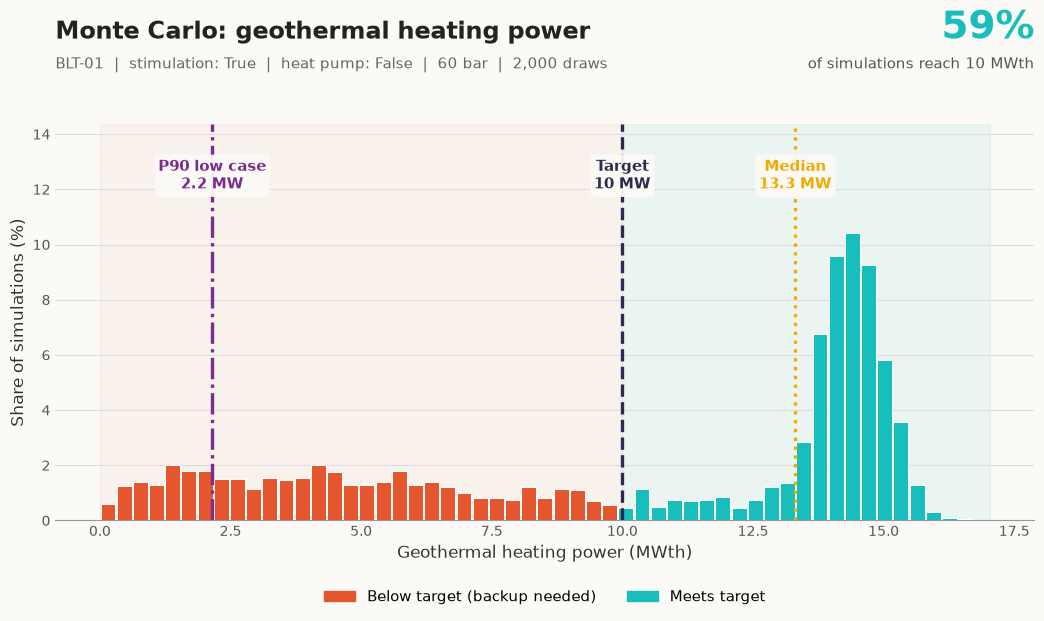

In [27]:
from matplotlib.patches import Patch

C_BELOW, C_ABOVE = "#E4572E", "#17BEBB"                 # below / above target
C_TARGET, C_MED, C_P90, C_BG = "#2E294E", "#F2A900", "#7B2D8E", "#FBFAF7"

p_meet = (x >= HEATING_TARGET).mean()
counts, edges = np.histogram(x, bins=np.linspace(0, x.max() * 1.02, 56))
centers, widths = (edges[:-1] + edges[1:]) / 2, np.diff(edges)
pct = counts / len(x) * 100                              # % of simulations per bin

fig, ax = plt.subplots(figsize=(11, 6.6))
fig.patch.set_facecolor(C_BG); ax.set_facecolor(C_BG)
fig.subplots_adjust(top=0.80, bottom=0.20, left=0.08, right=0.97)

ax.bar(centers, pct, width=widths * 0.92,
       color=np.where(centers >= HEATING_TARGET, C_ABOVE, C_BELOW),
       edgecolor="white", linewidth=0.7, zorder=3)
ax.axvspan(HEATING_TARGET, edges[-1], color=C_ABOVE, alpha=0.07, zorder=0)
ax.axvspan(edges[0], HEATING_TARGET, color=C_BELOW, alpha=0.05, zorder=0)

top = pct.max()
ax.set_ylim(0, top * 1.38)
for val, col, ls, label in [
        (st["P90_low"],    C_P90,    "-.", f"P90 low case\n{st['P90_low']:.1f} MW"),
        (HEATING_TARGET,   C_TARGET, "--", f"Target\n{HEATING_TARGET} MW"),
        (st["P50_median"], C_MED,    ":",  f"Median\n{st['P50_median']:.1f} MW")]:
    ax.axvline(val, color=col, linestyle=ls, linewidth=2.4, zorder=4)
    ax.text(val, top * 1.14, label, color=col, ha="center", va="bottom", fontsize=10.5,
            fontweight="bold", zorder=5,
            bbox=dict(boxstyle="round,pad=0.25", facecolor=C_BG, edgecolor="none", alpha=0.95))

# headline above the plot
fig.text(0.08, 0.93, "Monte Carlo: geothermal heating power", fontsize=17, fontweight="bold", color="#222")
fig.text(0.08, 0.885, f"{', '.join(wells)}  |  stimulation: {CHOICE['stim']}  |  heat pump: {CHOICE['hp']}  |  "
         f"{CHOICE['dP_bar']} bar  |  {len(x):,} draws", fontsize=10.5, color="#666")
fig.text(0.97, 0.93, f"{p_meet:.0%}", fontsize=28, fontweight="bold", color=C_ABOVE, ha="right")
fig.text(0.97, 0.885, f"of simulations reach {HEATING_TARGET} MWth", fontsize=10.5, color="#555", ha="right")

ax.set_xlabel("Geothermal heating power (MWth)", fontsize=12, color="#333")
ax.set_ylabel("Share of simulations (%)", fontsize=12, color="#333")
ax.grid(axis="y", color="#DDD", linewidth=0.8, zorder=1)
for sp in ["top", "right", "left"]: ax.spines[sp].set_visible(False)
ax.spines["bottom"].set_color("#999"); ax.tick_params(colors="#555", length=0)
ax.legend(handles=[Patch(color=C_BELOW, label="Below target (backup needed)"),
                   Patch(color=C_ABOVE, label="Meets target")],
          loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False, fontsize=11)
plt.show()
fig.savefig(FIG / "mc_power.png", dpi=200, bbox_inches="tight")